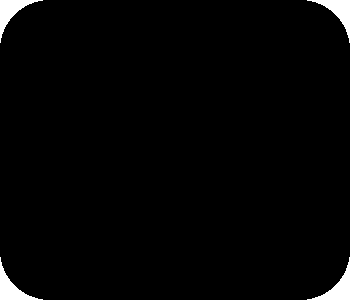

In [3]:
from pytamaro import(
    Graphic,
    Color,
    rotate,
    circular_sector,
    empty_graphic,
    rectangle,
    pin,
    center_right,
    center_left,
    bottom_left,
    top_left,
    compose,
    show_graphic,
    black)


def rounded_edge(width: float, corner_radius: float, color: Color) -> Graphic:
    assert width >= 0
    assert corner_radius >= 0
    assert corner_radius <= width / 2
    right = circular_sector(corner_radius, 90, color)
    left = rotate(90, right)
    body = empty_graphic() if corner_radius == width / 2 else rectangle(width - 2 * corner_radius, corner_radius, color)
    return compose(
        pin(center_right, left),
        pin(center_left, 
            compose(
                pin(center_right, body),
                pin(center_left, right)
            )
        )
    )

def rounded_rectangle(width: float, height: float, corner_radius: float, color: Color)-> Graphic:
    assert width > 0
    assert height > 0
    assert corner_radius >= 0
    assert corner_radius <= width / 2
    assert corner_radius <= height / 2

    if corner_radius == 0:
        return rectangle(width, height, color)
    else:
        edge = rounded_edge(width, corner_radius, color)
        body = empty_graphic() if corner_radius == height / 2 else rectangle(width, height - 2 * corner_radius, color)
        return compose(
            pin(bottom_left, edge),
            pin(top_left, 
                compose(
                    pin(bottom_left, body),
                    pin(top_left, rotate(180, edge))
                )
            )
        )


# code that shows result
show_graphic(rounded_rectangle(350, 300, 50, black))

